# NB05 — Battery model, optimiser, self-consumption benchmark and sizing

**SOLA4237 Assignment 2 — single-site battery optimisation, Toowoomba (QLD)**

**Purpose.** Introduce and test the battery model and optimiser in `bess_functions.py`, show that the default **self-consumption** mode
(the benchmark) is optimal for its own objective, and choose the battery size with a sweep on **2022** data (so 2023 stays out-of-sample
for PV and prices).

**Optimiser:** a linear program (LP) solved with `scipy.optimize.linprog` (HiGHS solver) — the same tool as the Week 7 battery LP.
Formulation: decision variables p_ch, p_dis, g_imp, g_exp, curt, E; power balance, SoC dynamics with charge/discharge
efficiency, SoC limits, power limits with temperature derating, curtailment only at negative prices.

**Operation:** every hour a 48 h hourly plan; every 5 min the battery follows the plan's grid target and direction
with the actual SoC; settlement with actual prices.

**Inputs:** `outputs/nb01_clean_2022_2023.csv`, `bess_functions.py` (in the Drive folder).
**Outputs:** `outputs/nb05_battery_parameters.csv`, `outputs/nb05_sizing_2022.csv`, figures fig08a–fig08b. **Run order:** after NB01.

## Cell 0 — Settings
`bess_functions.py` must be in the Drive folder

In [1]:
# Cell 0 - Settings: runs in Google Colab and in local Jupyter
import sys, os
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/SOLA4237-A2'
else:
    BASE_DIR = os.getcwd()                    # local: the data folder or its 'Notebook' subfolder
    if not os.path.exists(os.path.join(BASE_DIR, 'QLD_spot_price_2023')):
        BASE_DIR = os.path.dirname(BASE_DIR)
sys.path.append(BASE_DIR)
OUT_DIR = os.path.join(BASE_DIR, 'outputs')
FIG_DIR = os.path.join(OUT_DIR, 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
assert os.path.exists(os.path.join(BASE_DIR, 'bess_functions.py')), 'Upload bess_functions.py to ' + BASE_DIR
print('BASE_DIR:', BASE_DIR)

Mounted at /content/drive
BASE_DIR: /content/drive/MyDrive/SOLA4237-A2


## Cell 1 — Imports, data and battery parameters

In [2]:
# Cell 1 - imports, data, parameters
import time, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import bess_functions as bf
importlib.reload(bf)                         # pick up edits to the .py file without restarting

DT_H = 5 / 60
COL = {'flat': '#4c72b0', 'tou': '#55a868', 'wholesale': '#c44e52', 'soc': '#7f7f7f', 'load': '#1f4e79', 'pv': '#f2a900'}
TARIFFS = {'flat': ('import_flat_aud_kwh', 'export_flat_aud_kwh'),
           'tou': ('import_tou_aud_kwh', 'export_tou_aud_kwh'),
           'wholesale': ('import_wholesale_aud_kwh', 'export_wholesale_aud_kwh')}
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

df = pd.read_csv(os.path.join(OUT_DIR, 'nb01_clean_2022_2023.csv'), parse_dates=['datetime']).set_index('datetime')
y22 = df.loc['2022-01-01 00:05':'2023-01-01 00:00']          # 2022 in interval-ending labels
print('2022 rows:', len(y22))

sources = {'e_cap_kwh': 'Powerwall 2 AC datasheet [R20]', 'p_max_kw': '[R20]', 'eta_ch': 'sqrt(90 % round trip) [R20]',
           'eta_dis': 'sqrt(90 % round trip) [R20]', 'soc_min': 'course paper [R17]', 'soc_max': 'course paper [R17]',
           'soc0': 'modelling choice', 'c_deg': 'BESS operational cost [R18]', 'max_dis_kwh_day': '37.8 MWh / 3650 d warranty [R22]'}
params = pd.DataFrame({'value': bf.BATTERY, 'source': sources})
params

2022 rows: 105120


,value,source
e_cap_kwh,13.500,Powerwall 2 AC datasheet [R20]
p_max_kw,5.000,[R20]
eta_ch,0.949,sqrt(90 % round trip) [R20]
eta_dis,0.949,sqrt(90 % round trip) [R20]
soc_min,0.100,course paper [R17]
soc_max,0.950,course paper [R17]
soc0,0.500,modelling choice
c_deg,0.005,BESS operational cost [R18]
max_dis_kwh_day,10.400,37.8 MWh / 3650 d warranty [R22]


## Cell 2 — Temperature derating (Notes Q5/Q6)
Charging power is reduced linearly from 100 % at ≥ 10 °C to 0 % at 0 °C (ambient used as a conservative proxy for battery temperature).
**Check:** how often does it bind?

In [3]:
# Cell 2 - derating
k = bf.charge_derate(df['temperature_c'])
night = df.index.hour.isin([23, 0, 1, 2, 3, 4, 5, 6])
print('intervals with derated charging: %.1f %% of all, %.1f %% of night (23:00-07:00)' % (100 * (k < 1).mean(), 100 * (k[night] < 1).mean()))
print('lowest ambient temperature: %.1f C -> charge limit %.0f %% of %.1f kW' % (df.temperature_c.min(), 100 * k.min(), bf.BATTERY['p_max_kw']))

intervals with derated charging: 10.1 % of all, 22.2 % of night (23:00-07:00)
lowest ambient temperature: 1.8 C -> charge limit 18 % of 5.0 kW


## Cell 3 — Unit test with a known answer (like the Week 7 checks)
Four 1-hour steps, no load or PV: import price 0.10, 0.10, 0.50, 0.50 \$/kWh; export price 0, 0, 0.40, 0.40; start at 50 % SoC (6.75 kWh).
**Expected:** charge in the cheap hours up to the SoC limit (95 % = 12.825 kWh), discharge 5 kW in both expensive hours down towards 10 %,
and cost = charged energy × 0.10 − 10 kWh × 0.40 + 10 kWh × 0.005.

In [4]:
# Cell 3 - unit test
r = bf.solve_bess(load_kw=[0, 0, 0, 0], pv_kw=[0, 0, 0, 0], c_imp=[0.1, 0.1, 0.5, 0.5], c_exp=[0, 0, 0.4, 0.4],
                  k_ch=[1, 1, 1, 1], e_start_kwh=6.75, dt_h=1.0, mode='cost')
print(pd.DataFrame({k_: np.round(v, 3) for k_, v in r.items() if k_ not in ('cost', 'status')}))
charged = r['g_imp'].sum()
expected = charged * 0.10 - 10 * 0.40 + 10 * 0.005
print('LP cost %.4f | hand-calculated %.4f' % (r['cost'], expected))
assert np.allclose(r['p_dis'][2:], 5.0, atol=1e-6) and np.allclose(r['p_dis'][:2], 0, atol=1e-6)
assert abs(r['cost'] - expected) < 1e-6
assert r['E'].max() <= 0.95 * 13.5 + 1e-6 and r['E'].min() >= 0.10 * 13.5 - 1e-6
print('unit test passed')

    p_ch  p_dis  g_imp  g_exp  curt       E
0  0.413    0.0  0.413    0.0   0.0   7.142
1  5.000    0.0  5.000    0.0   0.0  11.887
2  0.000    5.0  0.000    5.0   0.0   6.619
3  0.000    5.0  0.000    5.0   0.0   1.350
LP cost -3.4087 | hand-calculated -3.4087
unit test passed


## Cell 4 — Benchmark: self-consumption as an optimisation (brief) and as a simple rule
**Default mode (brief):** maximise solar self-consumption = minimise grid import, with no grid charging and no battery export.
We solve it as an LP at 5-min resolution for one month with perfect foresight, and compare it with the simple rule used in
`run_operation(mode='selfcons')` (charge from surplus, discharge to cover deficit). **Expected:** identical grid import — so the rule *is*
the optimal self-consumption policy and is used as the benchmark S2 for the full year.

In [5]:
# Cell 4 - LP self-consumption vs rule (July 2022, winter: battery empties most nights)
m = df.loc['2022-07-01 00:05':'2022-08-01 00:00']
t0 = time.time()
lp = bf.solve_bess(m.load_kw, m.pv_actual_kw, np.zeros(len(m)), np.zeros(len(m)), bf.charge_derate(m.temperature_c),
                   e_start_kwh=bf.BATTERY['soc0'] * bf.BATTERY['e_cap_kwh'], dt_h=DT_H, mode='selfcons')
rule = bf.run_operation(m, *TARIFFS['flat'], mode='selfcons')
imp_lp, imp_rule = lp['g_imp'].sum() * DT_H, rule['import_kw'].sum() * DT_H
print('one-month LP (%d steps) solved in %.1f s' % (len(m), time.time() - t0))
print('grid import: LP %.2f kWh | rule %.2f kWh | difference %.3f kWh' % (imp_lp, imp_rule, imp_lp - imp_rule))
assert abs(imp_lp - imp_rule) < 0.5, 'rule and LP differ - check the model'

one-month LP (8928 steps) solved in 0.3 s
grid import: LP 697.01 kWh | rule 697.01 kWh | difference 0.000 kWh


## Cell 5 — Smoke test: one week of operation under each tariff (2022)
**Purpose:** see the behaviour before running whole years. S1 = PV only, S2 = self-consumption, S3 = cost-optimised (perfect foresight,
hourly plans, 5-min execution). **Checks:** energy balance error ≈ 0 and SoC within 10–95 %.
**What to look for:** S3 is not automatically cheaper than S2. S3 respects the warranty throughput cap (10.4 kWh/day discharged) and
plans on hourly averages, whereas S2 reacts every 5 min with no cap. The last lines repeat S3 **without** the cap to separate the two effects.

tariff                flat    tou  wholesale
scenario                                    
S1 PV only           66.63  65.03      73.73
S2 self-consumption  46.20  43.38      49.78
S3 cost-optimised    47.32  39.14      52.55
max energy-balance error (kW): 8.881784197001252e-16

S3 without the warranty throughput cap (same week):
  flat      46.49 $  (with cap 47.32 $)
  tou       35.86 $  (with cap 39.14 $)
  wholesale 49.24 $  (with cap 52.55 $)


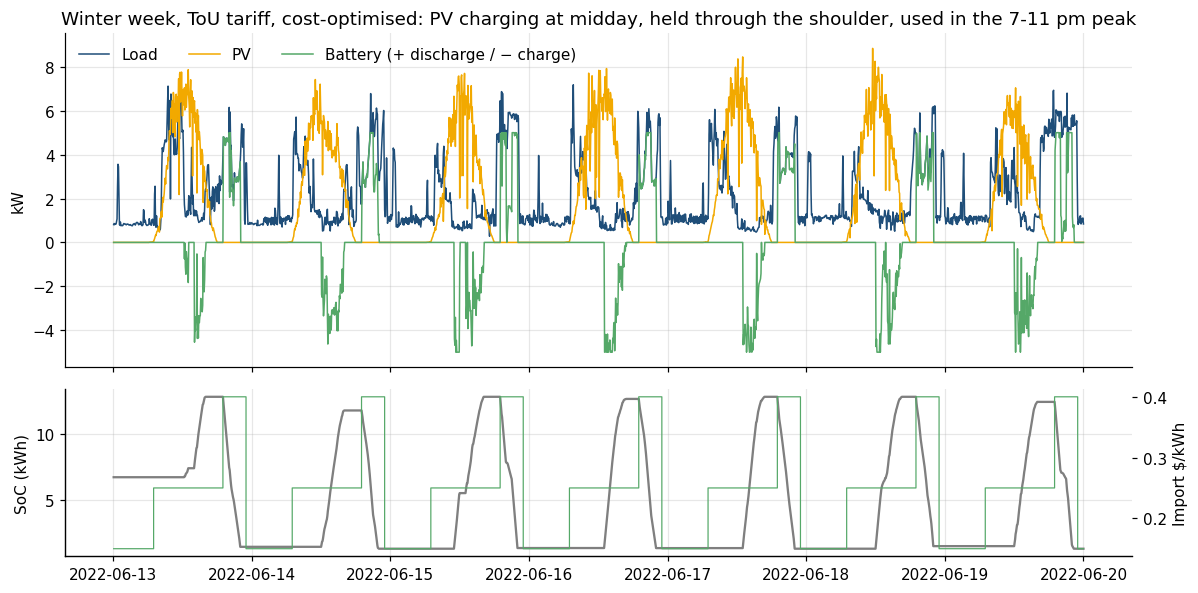

In [6]:
# Cell 5 - one-week smoke test
wk = df.loc['2022-06-13 00:05':'2022-06-20 00:00']           # a winter week
rows, runs_wk = [], {}
for tname, (ic, ec) in TARIFFS.items():
    s1 = bf.no_battery(wk, ic, ec)
    s2 = bf.run_operation(wk, ic, ec, mode='selfcons')
    s3 = bf.run_operation(wk, ic, ec, mode='cost', allow_curtail=(tname == 'wholesale'))
    runs_wk[tname] = s3
    for sname, res in [('S1 PV only', s1), ('S2 self-consumption', s2), ('S3 cost-optimised', s3)]:
        st = bf.settle(res)
        rows.append({'tariff': tname, 'scenario': sname, 'cost_aud': st['bill_aud'], 'import_kwh': st['import_kwh'],
                     'cycles': st['equivalent_full_cycles'], 'balance_err_kw': st['max_balance_error_kw']})
    assert s3['soc_kwh'].between(0.10 * 13.5 - 1e-6, 0.95 * 13.5 + 1e-6).all()
wk_table = pd.DataFrame(rows).pivot(index='scenario', columns='tariff', values='cost_aud')
print(wk_table.round(2))
print('max energy-balance error (kW):', max(r_['balance_err_kw'] for r_ in rows))
print('\nS3 without the warranty throughput cap (same week):')
for tname, (ic, ec) in TARIFFS.items():
    nocap = bf.run_operation(wk, ic, ec, mode='cost', allow_curtail=(tname == 'wholesale'), use_throughput_cap=False)
    print('  %-9s %.2f $  (with cap %.2f $)' % (tname, bf.settle(nocap)['bill_aud'], wk_table.loc['S3 cost-optimised', tname]))

# figure: ToU week, cost-optimised. Look for: when does it charge (PV or off-peak grid?) and when does it discharge?
res = runs_wk['tou']
fig, ax = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
ax[0].plot(res.index, res.load_kw, color=COL['load'], lw=1, label='Load')
ax[0].plot(res.index, res.pv_kw, color=COL['pv'], lw=1, label='PV')
ax[0].plot(res.index, res.p_bat_kw, color=COL['tou'], lw=1, label='Battery (+ discharge / − charge)')
ax[0].set_ylabel('kW'); ax[0].legend(ncol=3, frameon=False)
ax[0].set_title('Winter week, ToU tariff, cost-optimised: PV charging at midday, held through the shoulder, used in the 7-11 pm peak')
ax[1].plot(res.index, res.soc_kwh, color=COL['soc']); ax[1].set_ylabel('SoC (kWh)')
ax2 = ax[1].twinx(); ax2.step(res.index, res.import_price, color=COL['tou'], lw=0.8, where='post'); ax2.set_ylabel('Import $/kWh'); ax2.grid(False)
plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'fig08a_week_dispatch_tou.png'), dpi=200, bbox_inches='tight'); plt.show()

## Cell 6 — Sizing sweep on 2022 (economic view, Notes D.4.2)
For 5, 10, 13.5, 16 and 20 kWh (power = max(3 kW, 0.37 × capacity); warranty throughput scaled with capacity), run S2 (self-consumption)
and S3 (cost-optimised, perfect foresight) for each tariff over **2022**, and compute the annual saving vs PV only (S1).
To save time the sweep re-plans **once per day** (48 h plan, first 24 h executed); the final 2023 runs (NB06/NB07) re-plan hourly.

**Installed cost (incl. GST, installation and the Cheaper Home Batteries rebate):** Solar Choice Battery Price Index, May 2026 [R24]
(400+ installers): 5 kWh \$7,740, 10 kWh \$10,780, 13 kWh \$13,110, 16 kWh \$15,060, 20 kWh \$18,370.
We use one simple formula for any size: a **straight line through the 10 kWh and 20 kWh prices**:
- slope = (18,370 − 10,780) ÷ (20 − 10) = **\$759 per kWh** (the cost of each extra kWh of capacity);
- intercept = 10,780 − 759 × 10 = **\$3,190** (the fix cost: installation labour, inverter, wiring, margin).

So cost ≈ \$3,190 + \$759 × capacity, and 13.5 kWh ≈ **\$13,437**. Check: interpolating between the 13 and 16 kWh prices gives \$13,435,
and a least-squares line through all five prices gives \$13,507 (within 0.5 %). The index's "cost per kWh" is total price ÷ capacity, so it includes a share of the fixed cost and falls as size grows (\$1,550/kWh at 5 kWh, \$920/kWh
at 20 kWh). The table below compares the line with the index:
it is exact at 10 and 20 kWh, 0.4 % low at 13 kWh, 10 % low at 5 kWh and 2 % high at 16 kWh (so the 5 kWh payback is slightly optimistic).
Simple payback = cost ÷ annual saving. The \$300/yr VPP fee is *not* included here (it does not depend on size; NB08 includes it).

In [7]:
# Cell 6 - sizing sweep (2022)
SIZES = [5, 10, 13.5, 16, 20]
def installed_cost(e_kwh):
    # straight line through the Solar Choice index prices for 10 kWh ($10,780) and 20 kWh ($18,370), incl. rebate [R24]
    return 3190 + 759 * e_kwh

INDEX_PRICE = {5: 7740, 10: 10780, 13: 13110, 16: 15060, 20: 18370}          # Solar Choice index, May 2026 [R24]
check = pd.DataFrame({'index_price_aud': INDEX_PRICE, 'formula_aud': {k_: installed_cost(k_) for k_ in INDEX_PRICE}})
check['difference_%'] = 100 * (check.formula_aud / check.index_price_aud - 1)
print('Installed-cost formula vs Solar Choice index:'); print(check.round(1))
print('13.5 kWh: formula $%.0f | interpolation 13-16 kWh $%.0f' % (installed_cost(13.5), 13110 + (15060 - 13110) / 3 * 0.5))

s1_bill = {t: bf.settle(bf.no_battery(y22, ic, ec))['bill_aud'] for t, (ic, ec) in TARIFFS.items()}
rows = []
t0 = time.time()
for e in SIZES:
    b = bf.scaled_battery(e)
    for tname, (ic, ec) in TARIFFS.items():
        for mode in ['selfcons', 'cost']:
            res = bf.run_operation(y22, ic, ec, bat=b, mode=mode, allow_curtail=(tname == 'wholesale' and mode == 'cost'), replan_h=24)
            st = bf.settle(res, bat=b)
            saving = s1_bill[tname] - st['bill_aud']
            rows.append({'size_kwh': e, 'power_kw': b['p_max_kw'], 'tariff': tname, 'mode': mode, 'bill_aud': st['bill_aud'],
                         'saving_vs_S1_aud': saving, 'installed_cost_aud': installed_cost(e),
                         'payback_yr': installed_cost(e) / saving if saving > 0 else np.inf,
                         'cycles_per_yr': st['equivalent_full_cycles'], 'self_sufficiency': st['self_sufficiency']})
    print(f'size {e} kWh done ({time.time() - t0:.0f} s)')
sizing = pd.DataFrame(rows)
print('\nPV-only (S1) bills 2022:', {k_: round(v) for k_, v in s1_bill.items()})
print('\nAnnual saving vs S1 by operating mode ($):')
print(sizing.pivot_table(index='size_kwh', columns=['tariff', 'mode'], values='saving_vs_S1_aud').round(0))

Installed-cost formula vs Solar Choice index:
    index_price_aud  formula_aud  difference_%
5              7740         6985          -9.8
10            10780        10780           0.0
13            13110        13057          -0.4
16            15060        15334           1.8
20            18370        18370           0.0
13.5 kWh: formula $13436 | interpolation 13-16 kWh $13435
size 5 kWh done (11 s)
size 10 kWh done (22 s)
size 13.5 kWh done (33 s)
size 16 kWh done (44 s)
size 20 kWh done (55 s)

PV-only (S1) bills 2022: {'flat': 952, 'tou': 765, 'wholesale': 1399}

Annual saving vs S1 by operating mode ($):
tariff     flat             tou          wholesale         
mode       cost selfcons   cost selfcons      cost selfcons
size_kwh                                                   
5.0       327.0    371.0  371.0    350.0    1078.0    555.0
10.0      554.0    603.0  578.0    542.0    1739.0    847.0
13.5      657.0    699.0  690.0    635.0    2287.0    994.0
16.0      718.0   

## Cell 7 — Choose the size: saving and payback vs capacity
For each tariff we use the **better operating mode** from Cell 6 (a household would not run cost mode on a flat tariff, where there is
nothing to arbitrage and the warranty cap only takes value away).
**Rule:** compare the extra saving per extra kWh with its extra cost (\$759/kWh), then check against the energy and power views from NB02
(overnight need P50 ≈ 10.5 kWh, surplus ≥ 13.5 kWh on ~90 % of days, evening load ≤ 5 kW 96 % of the time).

better mode per tariff: {'flat': 'selfcons', 'tou': 'cost', 'wholesale': 'cost'}


/tmp/ipykernel_14294/724187200.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  best_mode = (sizing.groupby('tariff').apply(lambda d: d.groupby('mode').saving_vs_S1_aud.sum().idxmax()))


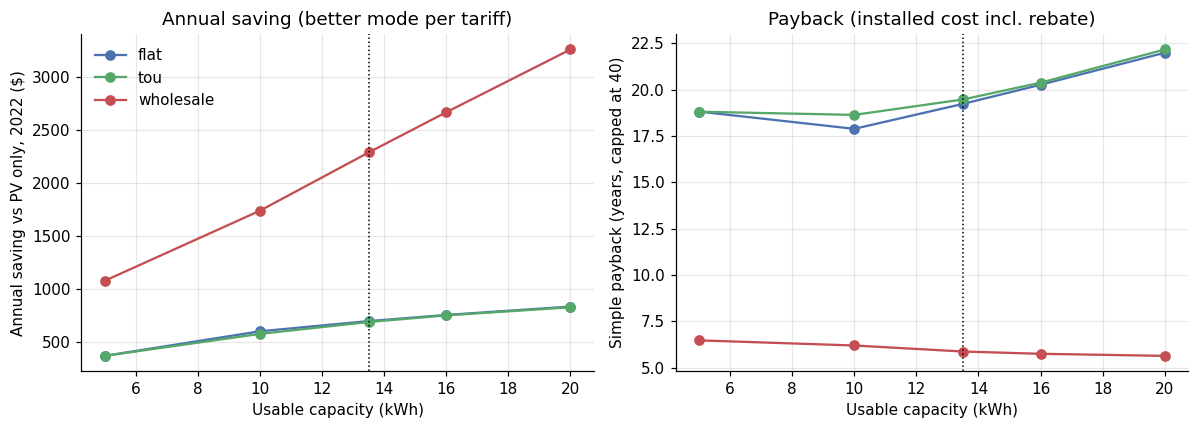

Extra annual saving per extra kWh of capacity ($/kWh/yr):
tariff    flat   tou  wholesale
size_kwh                       
5.0        NaN   NaN        NaN
10.0      46.3  41.4      132.1
13.5      27.4  31.9      156.6
16.0      23.2  25.0      151.5
20.0      19.7  19.1      147.9
Marginal installed cost: $759 per kWh -> an extra kWh pays back in 759 / (extra saving) years
tariff    flat   tou  wholesale
size_kwh                       
5.0        NaN   NaN        NaN
10.0      16.4  18.3        5.7
13.5      27.7  23.8        4.8
16.0      32.7  30.4        5.0
20.0      38.6  39.8        5.1


In [8]:
# Cell 7 - sizing figure and marginal saving
best_mode = (sizing.groupby('tariff').apply(lambda d: d.groupby('mode').saving_vs_S1_aud.sum().idxmax()))
print('better mode per tariff:', best_mode.to_dict())
cost_mode = pd.concat([sizing[(sizing.tariff == t) & (sizing['mode'] == m)] for t, m in best_mode.items()])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for tname in TARIFFS:
    d = cost_mode[cost_mode.tariff == tname]
    ax[0].plot(d.size_kwh, d.saving_vs_S1_aud, marker='o', color=COL[tname], label=tname)
    ax[1].plot(d.size_kwh, d.payback_yr.clip(upper=40), marker='o', color=COL[tname], label=tname)
for a in ax:
    a.axvline(13.5, color='k', ls=':', lw=1); a.set_xlabel('Usable capacity (kWh)')
ax[0].set_ylabel('Annual saving vs PV only, 2022 ($)'); ax[0].set_title('Annual saving (better mode per tariff)')
ax[1].set_ylabel('Simple payback (years, capped at 40)'); ax[1].set_title('Payback (installed cost incl. rebate)')
ax[0].legend(frameon=False)
plt.tight_layout(); fig.savefig(os.path.join(FIG_DIR, 'fig08b_sizing_2022.png'), dpi=200, bbox_inches='tight'); plt.show()

marg = cost_mode.pivot(index='size_kwh', columns='tariff', values='saving_vs_S1_aud')
marg_per_kwh = marg.diff().div(pd.Series(SIZES, index=SIZES).diff(), axis=0)
print('Extra annual saving per extra kWh of capacity ($/kWh/yr):'); print(marg_per_kwh.round(1))
print('Marginal installed cost: $759 per kWh -> an extra kWh pays back in 759 / (extra saving) years')
print((759 / marg_per_kwh).round(1))

## Cell 8 — Save

In [9]:
# Cell 8 - save
params.to_csv(os.path.join(OUT_DIR, 'nb05_battery_parameters.csv'))
sizing.to_csv(os.path.join(OUT_DIR, 'nb05_sizing_2022.csv'), index=False)
wk_table.to_csv(os.path.join(OUT_DIR, 'nb05_week_smoke_test.csv'))
print('saved nb05_battery_parameters.csv, nb05_sizing_2022.csv, nb05_week_smoke_test.csv')

saved nb05_battery_parameters.csv, nb05_sizing_2022.csv, nb05_week_smoke_test.csv


## AI-use record (Appendix A)
| Item | Entry |
|---|---|
| Tool & model | Claude Opus 5.5 (Anthropic), claude.ai |
| What AI did | Wrote bess_functions.py and this notebook from my notes; switched PuLP → scipy linprog because PuLP could not be tested |
| Example prompt | “NB04 done now proceed with notebook 5” |
| How I checked it | hand-checked the 4-step unit test; looked at the week plot; checked energy balance and SoC limits |